# 34 — Rotation and reflection consistency with the saved CNN

**Reuse the trained weights → encode all eight square orientations → rebuild the Earth/Moon cache → check transformed queries.** No training or scaler fitting occurs. Run this notebook before notebook 35 and copy its completed `ORIENTATION_RUN` path into notebook 35.

The four rotations (0°, 90°, 180°, 270°), plus those rotations after a left–right reflection, form eight orientations. We average their **individual model embeddings**, then normalize the mean. We transform all three scalar channels together: relative elevation, slope magnitude and local elevation SD. Physical heights, slopes and 960 m ground extent are preserved; no interpolation is needed.

This deliberately treats reflected terrain layouts as equivalent for the terrain-shape exercise. It does not handle arbitrary angles, shifted crops or camera viewpoints. Direction-dependent operations remain separate. The weights were trained with rotations only; this is a new inference policy, not a newly trained model or evidence of better relevance.

The default is the previously inspected full-context, region-balanced model. Only the approved development regions are loaded; final reserves remain unopened. All Earth development folds are pooled for the demonstration, not a final accuracy evaluation.

In [7]:
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from inspection import check_input, file_hash, verify_run
from processing import Run
from similarity_cnn import TerrainSimilarityCNN, cosine_top_k
from similarity_experiment import ROTATION_REFLECTION_POLICY, embed, load_view

SOURCE = ROOT / "data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6"
DATASET = ROOT / "data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac"
NOTEBOOK = ROOT / "notebooks/modeling/terrain_similarity/34_rotation_and_reflection_inference.ipynb"
VIEW = "full_context"
SAMPLING = "region_balanced"
QUERY_IDS = [
    "A3CLR22_10_Leibnitz_Beta_Plateau:full_context:144:112:960",
    "A3CLR22_2_Haworth:full_context:272:368:960",
    "A3CLR22_11_Malapert_Massif:full_context:432:368:960",
]
TOP_K = 3
DEVICE = torch.device("cpu")
TOLERANCE = 1e-5
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
assert VIEW in {"full_context", "image_supported"}
assert SAMPLING in {"region_balanced", "count_weighted"}
assert QUERY_IDS and len(set(QUERY_IDS)) == len(QUERY_IDS)
assert type(TOP_K) is int and 1 <= TOP_K <= 5
config = {"source": SOURCE.relative_to(ROOT).as_posix(), "dataset": DATASET.relative_to(ROOT).as_posix(),
          "view": VIEW, "sampling": SAMPLING, "query_ids": QUERY_IDS, "top_k": TOP_K,
          "inference_policy": ROTATION_REFLECTION_POLICY, "tolerance": TOLERANCE,
          "device": str(DEVICE), "reserves_opened": False}


## What the check establishes

For the three lunar examples and one Earth patch from each of the five development regions, compare every transformed input with its original input. Record embedding differences, changes in **all Earth-candidate cosine scores**, and exact top-three ordering. The eight-orientation policy must stay within `1e-5` for vectors and scores and retain the same top-three IDs in these examples. Near ties can be sensitive to floating-point arithmetic; the guarantee is mathematical invariance, with numerical tolerance in implementation.

The original four-rotation policy is shown alongside it. Earth patches in this mechanical check can retrieve themselves; this is not retrieval-accuracy evaluation. Comparing old and new lunar results only shows that rankings changed, not that they improved.

In [8]:
def orientation_checks(model, values, eight_bank, four_bank, patches, sample_indices, earth_indices):
    """Check unchanged scores/order under the eight spatial transformations."""
    samples = values[sample_indices]
    reference_eight = embed(model, samples, DEVICE, include_reflections=True)
    reference_four = embed(model, samples, DEVICE)
    ids = patches.iloc[earth_indices].patch_id.tolist()
    result = []
    for mirrored in (False, True):
        for turns in range(4):
            transformed = np.flip(samples, axis=-1) if mirrored else samples
            transformed = np.rot90(transformed, turns, axes=(-2, -1)).copy()
            for policy, current, reference, bank in [
                ("four_rotations", embed(model, transformed, DEVICE), reference_four, four_bank),
                (ROTATION_REFLECTION_POLICY, embed(model, transformed, DEVICE, include_reflections=True),
                 reference_eight, eight_bank),
            ]:
                for position, patch_index in enumerate(sample_indices):
                    order, _ = cosine_top_k(current[position], bank[earth_indices], ids, TOP_K)
                    original_order, _ = cosine_top_k(reference[position], bank[earth_indices], ids, TOP_K)
                    # Float64 normalized dot products inspect every candidate, not only top-k.
                    pool = bank[earth_indices].astype(float)
                    pool /= np.linalg.norm(pool, axis=1, keepdims=True)
                    current_unit = current[position].astype(float) / np.linalg.norm(current[position].astype(float))
                    original_unit = reference[position].astype(float) / np.linalg.norm(reference[position].astype(float))
                    score_delta = float(np.abs(pool @ current_unit - pool @ original_unit).max())
                    vector_delta = float(np.abs(current[position] - reference[position]).max())
                    same_order = bool(np.array_equal(order, original_order))
                    if policy == ROTATION_REFLECTION_POLICY:
                        assert vector_delta <= TOLERANCE and score_delta <= TOLERANCE and same_order
                    item = patches.iloc[patch_index]
                    result.append({"patch_id": item.patch_id, "body": item.body, "region": item.region,
                        "policy": policy, "mirrored": mirrored, "quarter_turns": turns,
                        "max_embedding_difference": vector_delta, "max_candidate_score_difference": score_delta,
                        "same_top_k_order": same_order, "top_k_ids": json.dumps([ids[i] for i in order])})
    return pd.DataFrame(result)


## Build a separate inference cache

The new cache records the exact source checkpoint hash, dataset, training scaler and inference policy. Both Moon and Earth receive the same eight-orientation transformation. Earlier caches and models remain valid for their original four-rotation policy; they must not be mixed with the new query embeddings.

The original saved vectors are also replayed on the selected lunar queries to check backward compatibility. A CPU/GPU difference up to `1e-4` is allowed for that replay; the new same-device orientation checks use the stricter tolerance above.

,examples,max_embedding_difference,max_candidate_score_difference,unchanged_top_k
policy,,,,
four_rotations,64,4.469665e-02,8.310398e-02,52
quarter_turns_and_reflections_v1,64,8.940697e-08,3.336674e-08,64


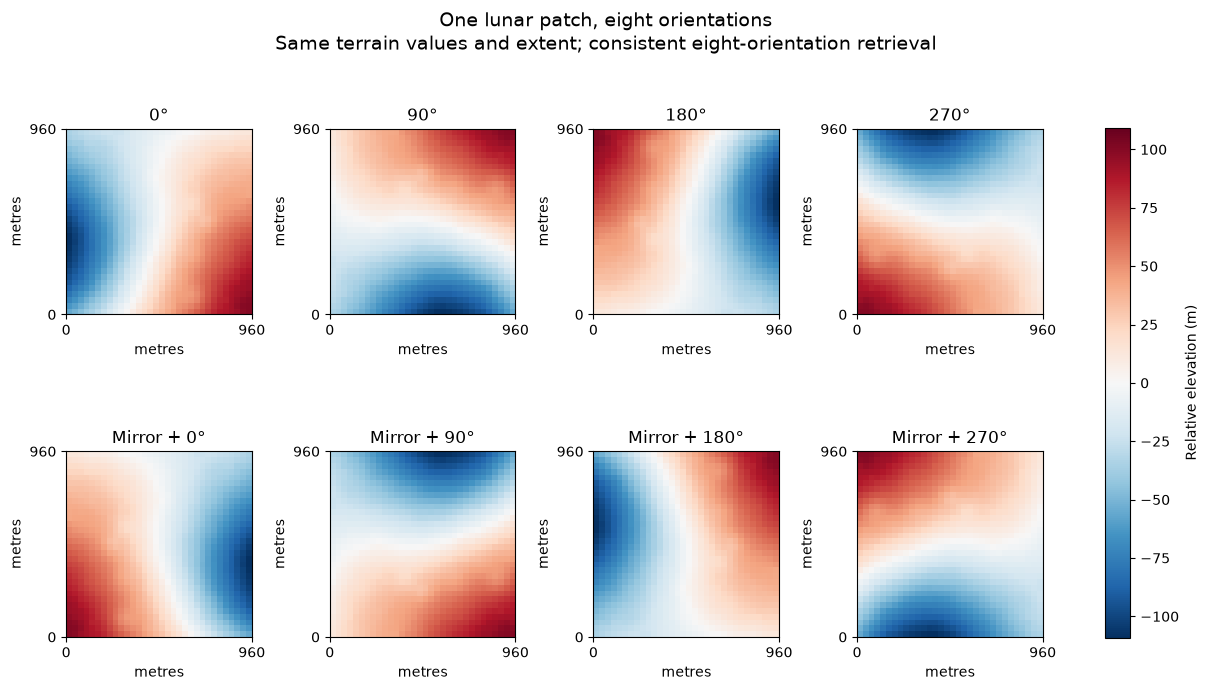

Completed cache and report: .\data\processed\terrain_similarity_orientation\20261102T143659566549Z_76c0b8
Copy this into notebook 35: data/processed/terrain_similarity_orientation/20261102T143659566549Z_76c0b8


In [9]:
with Run(ROOT, "terrain_similarity_orientation", config,
         "modeling/terrain_similarity/34_rotation_and_reflection_inference.ipynb") as run:
    run.record["torch"] = str(torch.__version__)
    run.record["role"] = "development proof of concept; orientation consistency, not relevance validation"
    for name in ("similarity_experiment.py", "similarity_cnn.py", "terrain_learning.py",
                 "terrain_dataset.py", "inspection.py", "retrieval_analysis.py"):
        run.input(ROOT / "notebooks" / name)
    run.input(SOURCE / "provenance.json")
    expected, evidence = verify_run(SOURCE), {}
    folder = SOURCE / VIEW / SAMPLING
    source_preprocessing = check_input(folder / "preprocessing.json", expected, evidence)
    preprocessing = json.loads(source_preprocessing.read_text(encoding="utf-8"))
    run.input(source_preprocessing)
    assert preprocessing["dataset_run"] == DATASET.relative_to(ROOT).as_posix()
    assert preprocessing["view"] == VIEW and preprocessing["input_shape"] == [3, 32, 32]
    patches, normalized, scaler, _ = load_view(DATASET, VIEW, run)
    assert scaler == preprocessing["scaler"]
    assert (patches.size_m == 960).all() and (patches.spacing_m == 30).all()
    assert set(QUERY_IDS) <= set(patches.loc[patches.body == "moon", "patch_id"])
    query_indices = pd.Index(patches.patch_id).get_indexer(QUERY_IDS)
    earth_indices = np.flatnonzero(patches.body.to_numpy() == "earth")
    assert len(earth_indices) == 5693 and patches.iloc[earth_indices].region.nunique() == 5
    checkpoint = check_input(folder / "model.pt", expected, evidence)
    run.input(checkpoint)
    model = TerrainSimilarityCNN().to(DEVICE)
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    saved_bank = check_input(folder / "embeddings.npz", expected, evidence)
    run.input(saved_bank)
    with np.load(saved_bank, allow_pickle=False) as archive:
        np.testing.assert_array_equal(archive["patch_ids"], patches.patch_id.to_numpy(dtype=str))
        four_bank = archive["cnn"].copy()
    assert four_bank.shape == (len(patches), 64) and np.isfinite(four_bank).all()
    np.testing.assert_allclose(np.linalg.norm(four_bank, axis=1), 1., atol=1e-5)
    replay = embed(model, normalized[query_indices], DEVICE)
    np.testing.assert_allclose(replay, four_bank[query_indices], atol=1e-4, rtol=0)
    earth_ids = patches.iloc[earth_indices].patch_id.tolist()
    for current, stored in zip(replay, four_bank[query_indices], strict=True):
        current_order, _ = cosine_top_k(current, four_bank[earth_indices], earth_ids, TOP_K)
        stored_order, _ = cosine_top_k(stored, four_bank[earth_indices], earth_ids, TOP_K)
        np.testing.assert_array_equal(current_order, stored_order)
    started = perf_counter()
    eight_bank = embed(model, normalized, DEVICE, include_reflections=True)
    run.record["encoding_seconds"] = perf_counter() - started
    np.testing.assert_allclose(np.linalg.norm(eight_bank, axis=1), 1., atol=1e-5)
    earth_samples = patches.loc[patches.body == "earth"].groupby("region", sort=True).head(1).index.to_numpy()
    sample_indices = np.concatenate([query_indices, earth_samples])
    checks = orientation_checks(model, normalized, eight_bank, four_bank, patches, sample_indices, earth_indices)
    checks.to_csv(run.path("orientation_checks.csv"), index=False)
    summary = checks.groupby("policy").agg(
        examples=("same_top_k_order", "size"), max_embedding_difference=("max_embedding_difference", "max"),
        max_candidate_score_difference=("max_candidate_score_difference", "max"),
        unchanged_top_k=("same_top_k_order", "sum"))
    summary.to_csv(run.path("orientation_summary.csv"))
    display(summary)
    comparison = []
    for query_index in query_indices:
        for policy, bank in [("four_rotations", four_bank), (ROTATION_REFLECTION_POLICY, eight_bank)]:
            order, scores = cosine_top_k(bank[query_index], bank[earth_indices], earth_ids, TOP_K)
            for rank, (position, score) in enumerate(zip(order, scores, strict=True), 1):
                comparison.append({"query_id": patches.iloc[query_index].patch_id, "policy": policy,
                    "rank": rank, "candidate_id": earth_ids[position], "cosine_similarity": float(score)})
    pd.DataFrame(comparison).to_csv(run.path("policy_comparison.csv"), index=False)
    np.savez_compressed(run.path("embeddings.npz"), patch_ids=patches.patch_id.to_numpy(dtype=str), cnn=eight_bank)
    patches.to_csv(run.path("patches.csv"), index=False)
    metadata = {**preprocessing, "inference_policy": ROTATION_REFLECTION_POLICY,
                "inference": "Mean of eight individual rotation/reflection embeddings, then L2 normalization",
                "source_checkpoint": checkpoint.relative_to(ROOT).as_posix(),
                "source_model_sha256": file_hash(checkpoint), "source_sampling": SAMPLING,
                "training_augmentation": "quarter-turn rotations only; no retraining",
                "orientation_checks_passed": True}
    run.path("preprocessing.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    # Restore physical units only for this explanatory gallery; CNN values remain normalized.
    relative_height = normalized[query_indices[0], 0] * scaler["scale"][0] + scaler["mean"][0]
    limit = float(np.abs(relative_height).max()) or 1.
    fig, axes = plt.subplots(2, 4, figsize=(12, 7), constrained_layout=True)
    for mirrored in (False, True):
        for turns in range(4):
            values = np.flip(relative_height, axis=-1) if mirrored else relative_height
            values = np.rot90(values, turns)
            ax = axes[int(mirrored), turns]
            panel = ax.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, extent=(0, 960, 0, 960))
            ax.set_title(f"{'Mirror + ' if mirrored else ''}{turns * 90}°")
            ax.set(xlabel="metres", ylabel="metres", xticks=[0, 960], yticks=[0, 960])
    fig.colorbar(panel, ax=axes.ravel().tolist(), label="Relative elevation (m)", shrink=.8)
    fig.suptitle("One lunar patch, eight orientations\nSame terrain values and extent; consistent eight-orientation retrieval", fontsize=14)
    fig.savefig(run.path("orientations.png"), dpi=125)
    plt.show()
    plt.close(fig)
    intro = "\n\n".join(c.source for c in nbformat.read(NOTEBOOK, as_version=4).cells if c.cell_type == "markdown")
    report = [intro, "![Eight orientations](orientations.png)", "## Measured consistency",
              "```text\n" + summary.to_string() + "\n```",
              "See orientation_checks.csv for every check and policy_comparison.csv for changed matches. These are consistency checks, not an accuracy improvement claim."]
    run.path("REPORT.md").write_text("\n\n".join(report) + "\n", encoding="utf-8")
ORIENTATION_RUN = run.directory
print("Completed cache and report:", ORIENTATION_RUN)
print("Copy this into notebook 35:", ORIENTATION_RUN.relative_to(ROOT).as_posix())
